# Industrial Surface Defect Classification using Transfer Learning 

**Name:** M Bulah
**Assignment:** Transfer Learning – Industrial Surface Defect Classification (NEU-DET)
**Notebook:** `Transfer_Learning_Surface_Defect_MBulah.ipynb`

## Objective

The aim of this assignment is to automatically classify surface defects in steel materials using real-world industrial image data and a transfer learning approach.

Surface defects such as cracks, scratches, inclusions, and pits commonly occur during manufacturing processes and can significantly affect product quality. Manual inspection of these defects is time-consuming, inconsistent, and difficult to scale.

In this assignment, we use a dataset containing steel surface images belonging to six different defect categories:
- Crazing  
- Inclusion  
- Patches  
- Pitted Surface  
- Rolled-in Scale  
- Scratches  

All defect types originate from the same manufacturing domain, and learning from all categories together allows the model to capture shared texture and structural patterns present across industrial surfaces.

The problem statement for this assignment is:

> **Given a steel surface image, predict the type of surface defect present in the image using a pretrained convolutional neural network.**

To solve this problem efficiently, we apply **transfer learning** by reusing a pretrained `MobileNetV2` model as a feature extractor and training only a lightweight classification head. This demonstrates how deep learning models can be adapted to real industrial use cases using limited data and computational resources.

## Business Value

In manufacturing industries such as steel, automotive, and heavy engineering, surface defects can directly impact product quality, safety, customer satisfaction, production cost, and rework rates.

Traditional inspection methods rely heavily on human inspectors, which introduces inconsistency in defect detection. Manual inspection also comes with high operational costs and scalability limitations.

By applying transfer learning, organisations can:
- Reuse pretrained visual intelligence instead of training models from scratch  
- Reduce development and training time  
- Achieve reliable defect detection even with smaller datasets  
- Deploy lightweight models suitable for real-time or edge-based inspection systems

## Dataset Description

This assignment uses the **NEU Surface Defect Dataset**, a real-world industrial dataset commonly used in manufacturing research and automated inspection systems.

### Dataset Characteristics:
- Images represent steel surface textures captured under industrial conditions  
- Each image belongs to one of six defect categories:
  - Crazing  
  - Inclusion  
  - Patches  
  - Pitted Surface  
  - Rolled-in Scale  
  - Scratches  
- Images are originally grayscale
- The dataset is reasonably balanced across classes  


#### Why this dataset?

- It represents a real industrial computer vision problem
- Defect patterns are texture-based, making it ideal for demonstrating transfer learning  
- The dataset size is moderate, encouraging the use of **partial transfer learning** rather than full model retraining  

## Flow Diagram

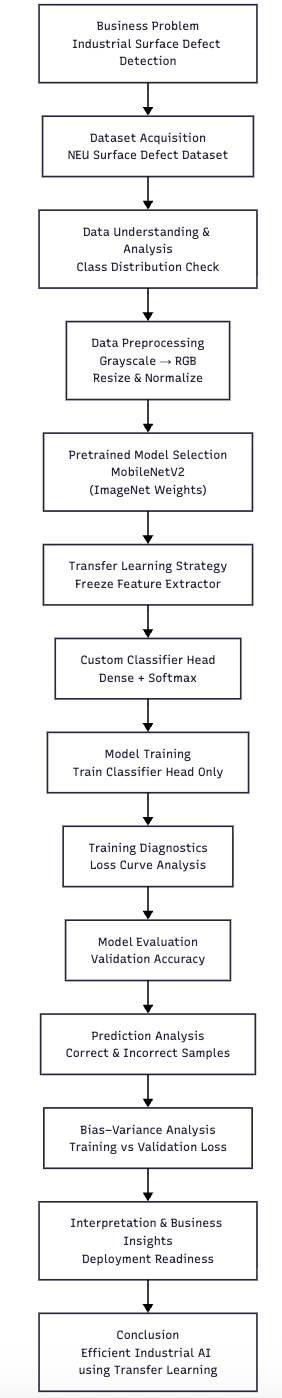

**Note:** You are free to choose any pre-trained model from the available ones. However, the architecture we suggest for this assignment is `MobileNetV2` with "ImageNet" weights.

The choice of libraries, frameworks, and backbones for this assignment are up to you. Before starting this assignment, please ensure that your environment meets the following requirements.


**Software Requirements**

- *Python version*: > Python3.11  
- *Execution environment*: Jupyter Notebook / JupyterLab / VS Code Notebook  
- *Operating system*: macOS, Linux, or Windows  


**Hardware Requirements**
- A GPU-powered training would be optimal, and would require installation of proper libraries and CUDA
- However, CPU-only execution might also be sufficient, and would work without CUDA

### Assumptions

1. **Framework:** PyTorch + torchvision is used throughout (TensorFlow is not used).
2. **Data location:** `NEU-DET.zip` is extracted next to this notebook, giving `NEU-DET/train/images/<class>/` and `NEU-DET/validation/images/<class>/`. If only the zip is present, the notebook extracts it automatically.
3. **Annotations:** The `annotations/` folders hold bounding-box XML files for object detection. This task is image-level classification, so they are not used; the label comes from the folder name only.
4. **Splits:** The provided split is used as-is (1,440 training images, 360 validation images). No separate test set is provided, so the validation set is used for final evaluation. It is **not** used for hyper-parameter search or early stopping, so the reported numbers are not tuned on it.
5. **Backbone:** `MobileNetV2` with ImageNet weights (`IMAGENET1K_V1`) is used, as suggested. Input resolution is 224×224 to match ImageNet pre-training, so the 200×200 images are upsampled.
6. **Grayscale → RGB:** The images contain grayscale content. The JPEG files in this copy of the dataset are stored with 3 identical channels (PIL mode `RGB`). `transforms.Grayscale(num_output_channels=3)` is still applied, so the pipeline always yields 3 identical channels whether a file is stored as 1-channel or 3-channel.
7. **Augmentation:** Light augmentation (horizontal/vertical flips) is applied to training images only. Steel-surface defects have no natural "up" or "left", so flipping keeps the class label valid.
8. **Frozen BatchNorm:** The whole feature extractor is frozen, including its BatchNorm running statistics. It is kept in `eval()` mode during training so ImageNet statistics are not overwritten.
9. **Reproducibility:** A fixed random seed (42) is set. Small run-to-run differences can still occur across hardware (CPU vs GPU).
10. **Execution note:** The outputs saved in this notebook were produced on CPU in an environment that could not reach `download.pytorch.org`. Equivalent ImageNet-trained MobileNetV2 weights with the identical architecture (from the public `d-li14/mobilenetv2.pytorch` release, 72.2% ImageNet top-1) were placed in the torch cache instead. Re-running the notebook normally downloads the official torchvision `IMAGENET1K_V1` weights, so the numbers may differ slightly.

### Import Necessary libraries

In [1]:
# Import Required Libraries
import os, random, time, zipfile, copy
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
import torchvision
from torchvision import datasets, transforms, models

from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             precision_recall_fscore_support)

# Reproducibility
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

sns.set_style("whitegrid")
print("PyTorch     :", torch.__version__)
print("Torchvision :", torchvision.__version__)
print("CUDA available:", torch.cuda.is_available())

PyTorch     : 2.14.1+cu130
Torchvision : 0.29.1+cu130
CUDA available: False


## 1. Data Loading and Preparation 

<font color=red>[10 marks]</font>

In any machine learning workflow, understanding and preparing the data correctly is a critical first step. Before building a deep learning model, it is important
to examine how the dataset is structured, how labels are assigned, and how images are preprocessed for training.

This section includes the following steps:
- Understanding the dataset organisation
- Verifying class labels and distributions
- Applying appropriate image transformations for transfer learning
- Development of train loader and validation loader

### 1.1 Dataset Understanding and Structure 

<font color=red>[4 marks]</font>

The NEU Surface Defect Dataset consists of real-world grayscale images collected from steel manufacturing processes. Each image belongs to one of six surface defect categories.

The dataset is already split into **training** and **validation** sets, and images are organised into class-specific folders. This structure allows us to use PyTorch’s `ImageFolder` utility, which automatically assigns labels based on directory names.

The same directory-based structure is also compatible with TensorFlow, allowing the dataset to be loaded directly using `tf.keras.utils.image_dataset_from_directory`, which infers class labels from folder names in a similar manner.



Before proceeding, we load the dataset and verify:
- Number of images in training and validation sets
- Mapping between class names and numeric labels

#### **1.1.1** Load Images and Labels  <font color=red>[3 marks]</font>

Load the training and validation datasets and check the number of images and the number of categories present

In [2]:
# Load training and validation images + labels
DATA_DIR = Path("NEU-DET")
if not DATA_DIR.exists() and Path("NEU-DET.zip").exists():      # assumption 2
    with zipfile.ZipFile("NEU-DET.zip") as zf:
        zf.extractall(".")

TRAIN_DIR = DATA_DIR / "train" / "images"
VAL_DIR   = DATA_DIR / "validation" / "images"

# ImageFolder assigns labels from the folder names (sorted alphabetically)
train_raw = datasets.ImageFolder(TRAIN_DIR)
val_raw   = datasets.ImageFolder(VAL_DIR)

class_names = train_raw.classes
num_classes = len(class_names)
assert train_raw.class_to_idx == val_raw.class_to_idx, "Train/val label mapping differs!"

# Dataset statistics
print(f"Number of training images   : {len(train_raw)}")
print(f"Number of validation images : {len(val_raw)}")
print(f"Total images                : {len(train_raw) + len(val_raw)}")
print(f"Number of categories        : {num_classes}")
print("\nClass name -> numeric label mapping:")
for name, idx in train_raw.class_to_idx.items():
    print(f"  {idx}: {name}")

# Inspect raw image properties
sample_img = Image.open(train_raw.samples[0][0])
sizes = Counter(Image.open(p).size for p, _ in train_raw.samples[::40])
modes = Counter(Image.open(p).mode for p, _ in train_raw.samples[::40])
print(f"\nSample image size: {sample_img.size}, mode: {sample_img.mode}")
print("Sizes seen (sample of files):", dict(sizes))
print("Modes seen (sample of files):", dict(modes))

Number of training images   : 1440
Number of validation images : 360
Total images                : 1800
Number of categories        : 6

Class name -> numeric label mapping:
  0: crazing
  1: inclusion
  2: patches
  3: pitted_surface
  4: rolled-in_scale
  5: scratches

Sample image size: (200, 200), mode: RGB
Sizes seen (sample of files): {(200, 200): 36}
Modes seen (sample of files): {'RGB': 36}


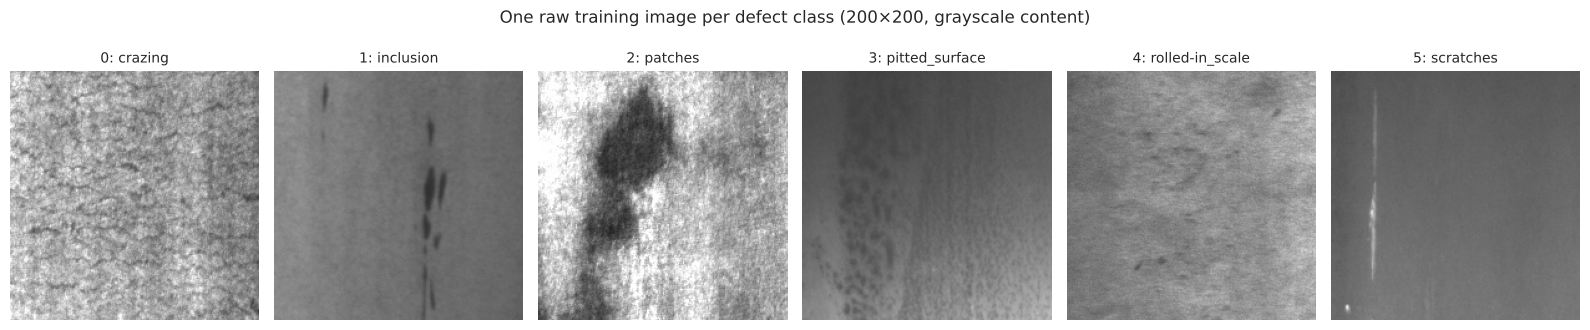

In [3]:
# Show one raw example from each class
fig, axes = plt.subplots(1, num_classes, figsize=(16, 3.2))
for c, ax in enumerate(axes):
    path = next(p for p, y in train_raw.samples if y == c)
    ax.imshow(Image.open(path), cmap="gray")
    ax.set_title(f"{c}: {class_names[c]}", fontsize=10)
    ax.axis("off")
plt.suptitle("One raw training image per defect class (200×200, grayscale content)", y=1.03)
plt.tight_layout()
plt.show()

Here, the image loader automatically assigns numeric labels based on folder names. For example, all images inside the "crazing" folder receive the same label.

This approach reduces manual labeling effort and ensures consistency between directory structure and class definitions.

#### **1.1.2** Check and Visualise Class Distribution <font color=red>[1 mark]</font>

In [4]:
# Dataset Class Distribution
train_counts = Counter(train_raw.targets)
val_counts   = Counter(val_raw.targets)

dist_df = pd.DataFrame({
    "class": class_names,
    "label": range(num_classes),
    "train": [train_counts[i] for i in range(num_classes)],
    "validation": [val_counts[i] for i in range(num_classes)],
})
dist_df["total"] = dist_df["train"] + dist_df["validation"]
dist_df["train %"] = (dist_df["train"] / dist_df["train"].sum() * 100).round(2)
dist_df["validation %"] = (dist_df["validation"] / dist_df["validation"].sum() * 100).round(2)
display(dist_df)
print(f"Imbalance ratio (max/min) - train: {max(train_counts.values())/min(train_counts.values()):.2f}, "
      f"validation: {max(val_counts.values())/min(val_counts.values()):.2f}")

,class,label,train,validation,total,train %,validation %
0,crazing,0,240,60,300,16.67,16.67
1,inclusion,1,240,60,300,16.67,16.67
2,patches,2,240,60,300,16.67,16.67
3,pitted_surface,3,240,60,300,16.67,16.67
4,rolled-in_scale,4,240,60,300,16.67,16.67
5,scratches,5,240,60,300,16.67,16.67


Imbalance ratio (max/min) - train: 1.00, validation: 1.00


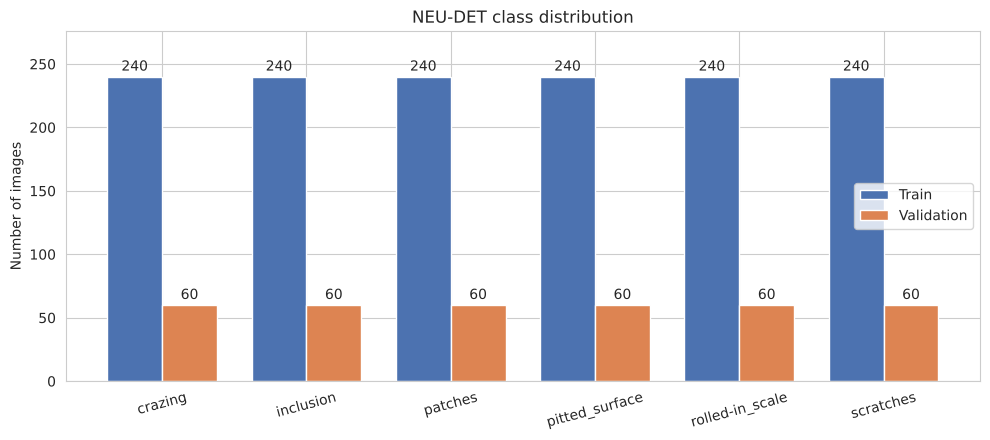

In [5]:
# Visualise class distribution
fig, ax = plt.subplots(figsize=(10, 4.5))
x = np.arange(num_classes); w = 0.38
b1 = ax.bar(x - w/2, dist_df["train"], w, label="Train", color="#4C72B0")
b2 = ax.bar(x + w/2, dist_df["validation"], w, label="Validation", color="#DD8452")
ax.bar_label(b1, padding=2); ax.bar_label(b2, padding=2)
ax.set_xticks(x); ax.set_xticklabels(class_names, rotation=15)
ax.set_ylabel("Number of images"); ax.set_title("NEU-DET class distribution")
ax.set_ylim(0, dist_df["train"].max() * 1.15)
ax.legend()
plt.tight_layout(); plt.show()

**Observation:** The dataset is perfectly balanced: 240 training and 60 validation images per class, an 80/20 split. Every class is 16.67% of each split. Because of this:
- No class weighting or resampling is needed, and plain cross-entropy loss is appropriate.
- Accuracy is a fair headline metric, since a model cannot score well by favouring a majority class. A random guess would get about 16.7%.

### 1.2 Data Preprocessing and Transformations 

<font color=red>[6 marks]</font>

Deep learning models pretrained on ImageNet expect images to be in a specific format. Although the NEU dataset images are grayscale, ImageNet-pretrained models require 3-channel RGB images with standardised dimensions and normalisation.

#### **1.2.1** Apply Image Transformations <font color=red>[4 marks]</font>

To ensure compatibility, we apply the following transformations:
- Convert grayscale images to RGB
- Resize images to a fixed resolution
- Normalize using ImageNet mean and standard deviation

These transformations are provided in [`transforms`](https://docs.pytorch.org/vision/0.24/transforms.html) from `torchvision`, while in TensorFlow the same preprocessing steps are applied using [`tf.image`](https://www.tensorflow.org/api_docs/python/tf/image) operations and `tf.keras.layers` within the input pipeline.

In PyTorch, normalization can be performed using `Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD)`.

In TensorFlow, the same effect is achieved by explicitly standardising the images with the ImageNet statistics, i.e. subtracting `IMAGENET_MEAN` and dividing by `IMAGENET_STD` using `tf.image` operations or a custom `tf.keras.layers.Layer` within the preprocessing pipeline.

In [6]:
# Image Transformations
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]
IMG_SIZE = 224   # MobileNetV2 was pre-trained at 224x224

# Training: grayscale->RGB, resize, light geometric augmentation, tensor, ImageNet normalisation
train_transforms = transforms.Compose([
    transforms.Grayscale(num_output_channels=3),   # 1 channel -> 3 identical channels
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),        # defects are orientation-agnostic
    transforms.RandomVerticalFlip(p=0.5),
    transforms.ToTensor(),                          # [0,255] -> [0,1], HWC -> CHW
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

# Validation: deterministic - no augmentation
val_transforms = transforms.Compose([
    transforms.Grayscale(num_output_channels=3),
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

train_dataset = datasets.ImageFolder(TRAIN_DIR, transform=train_transforms)
val_dataset   = datasets.ImageFolder(VAL_DIR,   transform=val_transforms)

x0, y0 = train_dataset[0]
print("Transformed tensor shape:", tuple(x0.shape), "| dtype:", x0.dtype, "| label:", y0, f"({class_names[y0]})")
print("Per-channel mean after normalisation:", x0.mean(dim=(1, 2)).numpy().round(3))
print("Per-channel std  after normalisation:", x0.std(dim=(1, 2)).numpy().round(3))
print("\nTrain transforms:\n", train_transforms)
print("\nValidation transforms:\n", val_transforms)

Transformed tensor shape: (3, 224, 224) | dtype: torch.float32 | label: 0 (crazing)
Per-channel mean after normalisation: [0.633 0.777 0.996]
Per-channel std  after normalisation: [0.457 0.467 0.465]

Train transforms:
 Compose(
    Grayscale(num_output_channels=3)
    Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
    RandomHorizontalFlip(p=0.5)
    RandomVerticalFlip(p=0.5)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)

Validation transforms:
 Compose(
    Grayscale(num_output_channels=3)
    Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)


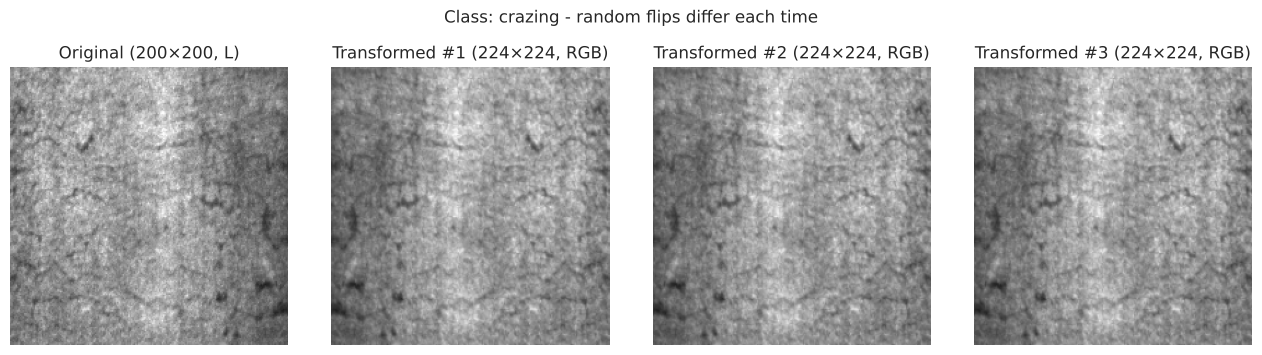

In [7]:
# Visual check: same image before and after the training transforms (de-normalised for display)
def denormalize(t):
    mean = torch.tensor(IMAGENET_MEAN).view(3, 1, 1); std = torch.tensor(IMAGENET_STD).view(3, 1, 1)
    return (t * std + mean).clamp(0, 1).permute(1, 2, 0).numpy()

idx = 5
fig, axes = plt.subplots(1, 4, figsize=(13, 3.4))
axes[0].imshow(Image.open(train_raw.samples[idx][0]), cmap="gray"); axes[0].set_title("Original (200×200, L)")
for k in range(1, 4):
    axes[k].imshow(denormalize(train_dataset[idx][0])); axes[k].set_title(f"Transformed #{k} (224×224, RGB)")
for a in axes: a.axis("off")
plt.suptitle(f"Class: {class_names[train_raw.samples[idx][1]]} - random flips differ each time", y=1.03)
plt.tight_layout(); plt.show()

At this stage, the dataset is fully prepared for training a transfer learning model. Images are correctly formatted, normalized, and labeled, ensuring a smooth transition into model design and training.

#### **1.2.2** Create DataLoaders for both the training and validation datasets <font color=red>[2 marks]</font>


Deep learning models are trained on data in **batches** rather than loading the entire dataset into memory at once.

PyTorch provides the [`DataLoader`](https://docs.pytorch.org/docs/stable/data.html#torch.utils.data.DataLoader) utility to batch the data, shuffle training samples and load data efficiently during training. For Tensorflow, you can use similar functionality provided by [`tf.data.Dataset` API](https://www.tensorflow.org/api_docs/python/tf/data/Dataset), which supports efficient batching, shuffling, prefetching, and parallel data loading within the input pipeline.

In [8]:
# DataLoader Creation
BATCH_SIZE = 32
NUM_WORKERS = 2
g = torch.Generator().manual_seed(SEED)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=NUM_WORKERS, generator=g, pin_memory=torch.cuda.is_available())
val_loader   = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False,
                          num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available())

images, labels = next(iter(train_loader))
print(f"Train batches: {len(train_loader)} | Validation batches: {len(val_loader)}")
print("One training batch - images:", tuple(images.shape), "| labels:", tuple(labels.shape))
print("Labels in first batch:", labels.tolist())

Train batches: 45 | Validation batches: 12
One training batch - images: (32, 3, 224, 224) | labels: (32,)
Labels in first batch: [5, 4, 2, 5, 1, 3, 4, 3, 0, 1, 3, 1, 5, 0, 2, 1, 0, 0, 4, 4, 2, 2, 5, 5, 2, 4, 5, 0, 4, 3, 0, 2]


Also decide on where to use shuffling - training or validation

**Answer – where to shuffle:** Shuffling is used **only for the training loader** (`shuffle=True`).
- **Training:** `ImageFolder` returns images grouped by class. Without shuffling, every batch would contain only one class and the gradients would swing back and forth between classes. Reshuffling each epoch gives mixed-class batches, more stable updates and better generalisation. The first batch above already mixes several labels.
- **Validation:** `shuffle=False`. Evaluation does not update weights, so order does not affect the metrics. A fixed order also keeps predictions aligned with `val_dataset.samples`, which is needed for the per-image analysis in Section 3.2.

## 2. Transferring Knowledge and Model Training

<font color=red>[25 marks]</font>

Training deep learning models from scratch requires large amounts of labeled data and computational resources. In many real-world scenarios, this is not feasible. Transfer learning addresses this challenge by reusing knowledge learned from a large source dataset (such as ImageNet) and adapting it to a new, related task.

### 2.1 Pretrained Model Selection

<font color=red>[15 marks]</font>

For this assignment, we will prefer **MobileNetV2**, a lightweight convolutional neural network pretrained on the ImageNet dataset. Though any pre-trained network will suit the task.

MobileNetV2 is computationally efficient and lightweight. It performs well on texture-based image classification tasks.

In this section:
- Select a suitable pretrained convolutional neural network
- Apply a partial transfer learning strategy
- Design a task-specific classifier for surface defect detection

#### **2.1.1** Load the Pre-Trained Model <font color=red>[5 marks]</font>

Load the pre-trained model of your choice. If you wish to use a different architecture from MobileNet, also explain the reason for your choice.

In [9]:
# Load Pretrained Network
weights = models.MobileNet_V2_Weights.IMAGENET1K_V1
base_model = models.mobilenet_v2(weights=weights)

total_base = sum(p.numel() for p in base_model.parameters())
print(f"Loaded MobileNetV2 with weights: {weights}")
print(f"Total parameters (original 1000-class model): {total_base:,}")
print(f"Feature-extractor blocks: {len(base_model.features)}")
print("\nOriginal ImageNet classifier head:")
print(base_model.classifier)

# Sanity check: feature map size for a 224x224 input
with torch.no_grad():
    fmap = base_model.features(torch.zeros(1, 3, IMG_SIZE, IMG_SIZE))
print("\nFeature-extractor output shape for one 224x224 image:", tuple(fmap.shape))

Loaded MobileNetV2 with weights: MobileNet_V2_Weights.IMAGENET1K_V1
Total parameters (original 1000-class model): 3,504,872
Feature-extractor blocks: 19

Original ImageNet classifier head:
Sequential(
  (0): Dropout(p=0.2, inplace=False)
  (1): Linear(in_features=1280, out_features=1000, bias=True)
)



Feature-extractor output shape for one 224x224 image: (1, 1280, 7, 7)


**Why MobileNetV2 (the suggested model) was kept:**
- **Lightweight:** about 3.5M parameters and about 300M multiply-adds. That is roughly 7× fewer parameters than ResNet-50, which suits CPU training and later edge deployment on an inspection line.
- **Design (Sandler et al., 2018):** *inverted residual blocks with linear bottlenecks* use depthwise-separable convolutions. They keep rich low-level features (edges, textures, blobs) that transfer well to texture-based defect images.
- **Strong ImageNet features:** About 72% top-1 on ImageNet gives a good general-purpose visual vocabulary to reuse.
- The feature extractor turns a 224×224×3 image into a **7×7×1280** feature map. The original head (Dropout + Linear 1280→1000) is ImageNet-specific and is replaced in the next step.

The MobileNetV2 architecture consists of two main components:
- A **feature extractor** that learns visual representations
- A **classifier head** originally designed for ImageNet’s 1000 classes

#### **2.1.2** Freezing Strategy and Classifier Design <font color=red>[8 marks]</font>

Build the transfer learning model by loading and freezing the feature extractor layers. 


Instead of retraining the entire network, we apply partial transfer learning. In this approach the pretrained feature extractor is frozen and only the classifier head is retrained for the new task. This strategy reduces the risk of overfitting and speeds up training.

In [10]:
# Build Transfer Learning Model
def build_transfer_model(num_classes: int) -> nn.Module:
    model = models.mobilenet_v2(weights=models.MobileNet_V2_Weights.IMAGENET1K_V1)

    # 1) Freeze the entire pretrained feature extractor
    for param in model.features.parameters():
        param.requires_grad = False

    # 2) Replace the 1000-class ImageNet head with a small task-specific head
    in_features = model.classifier[1].in_features          # 1280
    model.classifier = nn.Sequential(
        nn.Dropout(p=0.3),
        nn.Linear(in_features, 256),
        nn.ReLU(inplace=True),
        nn.Dropout(p=0.3),
        nn.Linear(256, num_classes),                        # 6 defect classes (raw logits)
    )
    return model

model = build_transfer_model(num_classes)
print(model.classifier)

Sequential(
  (0): Dropout(p=0.3, inplace=False)
  (1): Linear(in_features=1280, out_features=256, bias=True)
  (2): ReLU(inplace=True)
  (3): Dropout(p=0.3, inplace=False)
  (4): Linear(in_features=256, out_features=6, bias=True)
)


**Freezing strategy and classifier design:**
- **Frozen:** all 19 blocks of `model.features`, covering every convolution and BatchNorm layer (`requires_grad=False`). These layers work as a fixed, general-purpose texture and shape descriptor learned on ImageNet. During training this part is also put in `eval()` mode, so BatchNorm keeps its ImageNet running mean and variance (assumption 7).
- **Trainable:** a new head, `Dropout(0.3) → Linear(1280→256) → ReLU → Dropout(0.3) → Linear(256→6)`. MobileNetV2's global average pooling sits before the classifier.
  - The 256-unit hidden layer lets the head learn non-linear combinations of ImageNet features. Steel textures look quite different from natural photos, so this adds useful capacity.
  - Dropout regularises the head, because 1,440 training images is small.
  - No softmax in the head: `CrossEntropyLoss` expects raw logits and applies log-softmax internally.
- **Why partial transfer learning:** With only 1,440 images, retraining 2.2M backbone weights would risk overfitting and cost much more compute. Training about 0.33M head parameters is fast and data-efficient.

#### **2.1.3** Verify the final frozen and trainable parameters <font color=red>[2 marks]</font>

In [11]:
# Verify Freezing Strategy
def count_params(module):
    total = sum(p.numel() for p in module.parameters())
    trainable = sum(p.numel() for p in module.parameters() if p.requires_grad)
    return total, trainable, total - trainable

rows = []
for name, part in [("features (backbone)", model.features), ("classifier (new head)", model.classifier), ("FULL MODEL", model)]:
    t, tr, fr = count_params(part)
    rows.append({"component": name, "total params": f"{t:,}", "trainable": f"{tr:,}", "frozen": f"{fr:,}",
                 "% trainable": f"{100 * tr / t:.2f}%"})
display(pd.DataFrame(rows))

# Every tensor that will receive gradients
print("Trainable parameter tensors:")
for n, p in model.named_parameters():
    if p.requires_grad:
        print(f"  {n:25s} {tuple(p.shape)}")

assert all(not p.requires_grad for p in model.features.parameters()), "Backbone is not fully frozen!"
assert all(p.requires_grad for p in model.classifier.parameters()), "Head is not fully trainable!"
print("\n✔ Backbone fully frozen, classifier head fully trainable.")

,component,total params,trainable,frozen,% trainable
0,features (backbone),"2,223,872",0,"2,223,872",0.00%
1,classifier (new head),"329,478","329,478",0,100.00%
2,FULL MODEL,"2,553,350","329,478","2,223,872",12.90%


Trainable parameter tensors:
  classifier.1.weight       (256, 1280)
  classifier.1.bias         (256,)
  classifier.4.weight       (6, 256)
  classifier.4.bias         (6,)

✔ Backbone fully frozen, classifier head fully trainable.


### 2.2 Model Training 

<font color=red>[10 marks]</font>

After designing the transfer learning model, the next step is to train it on the prepared dataset.

We only train the classifier head, while the pretrained feature extractor remains frozen. This allows the model to adapt quickly to the surface defect classification task.

In this section, we:
- Configure the training setup
- Train the model for a small number of epochs
- Track training loss to verify learning progress

#### **2.2.1** Training Configuration <font color=red>[3 marks]</font>

Before starting the training loop, we define:
- The computation device: CPU or GPU
- The loss function: Use a suitable loss function (one of the cross-entropy losses would work fine here)
- The optimizer: preferably [Adam](https://arxiv.org/abs/1412.6980) from [Tensorflow](https://www.tensorflow.org/api_docs/python/tf/keras/optimizers/Adam) or [Pytorch](https://docs.pytorch.org/docs/stable/generated/torch.optim.Adam.html)

These components control how the model learns from data and how its parameters are updated during training.

In [12]:
# Training Configuration
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)

criterion = nn.CrossEntropyLoss()                     # multi-class, balanced data -> no class weights
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4
optimizer = optim.Adam(filter(lambda p: p.requires_grad, model.parameters()),   # only the head
                       lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
NUM_EPOCHS = 10

print("Device        :", device)
print("Loss function :", criterion)
print("Optimizer     :", optimizer.__class__.__name__, f"(lr={LEARNING_RATE}, weight_decay={WEIGHT_DECAY})")
print("Params optimised:", sum(p.numel() for g_ in optimizer.param_groups for p in g_["params"]))
print("Epochs        :", NUM_EPOCHS, "| Batch size:", BATCH_SIZE)

Device        : cpu
Loss function : CrossEntropyLoss()
Optimizer     : Adam (lr=0.001, weight_decay=0.0001)
Params optimised: 329478
Epochs        : 10 | Batch size: 32


**Configuration choices:**
- **Device:** GPU if available, otherwise CPU. With the backbone frozen, CPU training takes only a few minutes.
- **Loss:** `CrossEntropyLoss`, the standard loss for single-label multi-class classification. No class weights are needed because the classes are balanced.
- **Optimizer:** Adam with learning rate 1e-3, a typical default for a freshly initialised head. A small weight decay (1e-4) adds L2 regularisation. Only parameters with `requires_grad=True` are passed to the optimizer, so the backbone cannot change.
- **Epochs:** 10. A frozen backbone with a small head converges quickly, so a short schedule is enough.

#### **2.2.2** Model Training Loop <font color=red>[5 marks]</font>

Perform the training and track the training loss across epochs to verify whether the model is learning effectively.

The training loop iterates over the dataset multiple times (epochs). For each batch of images, the model:
- Performs a forward pass
- Computes the loss
- Updates the trainable parameters using backpropagation

In [13]:
# Model Training
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()
    model.features.eval()          # keep frozen BatchNorm layers in inference mode
    running_loss, correct, n = 0.0, 0, 0
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(images)                 # forward pass
        loss = criterion(outputs, labels)       # compute loss
        loss.backward()                         # backpropagation (head only)
        optimizer.step()                        # update trainable parameters
        running_loss += loss.item() * images.size(0)
        correct += (outputs.argmax(1) == labels).sum().item()
        n += images.size(0)
    return running_loss / n, correct / n

@torch.no_grad()
def evaluate(model, loader, criterion, device):
    model.eval()
    running_loss, correct, n = 0.0, 0, 0
    all_preds, all_labels, all_probs = [], [], []
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        running_loss += criterion(outputs, labels).item() * images.size(0)
        probs = outputs.softmax(1)
        preds = probs.argmax(1)
        correct += (preds == labels).sum().item(); n += images.size(0)
        all_preds.append(preds.cpu()); all_labels.append(labels.cpu()); all_probs.append(probs.cpu())
    return (running_loss / n, correct / n,
            torch.cat(all_preds).numpy(), torch.cat(all_labels).numpy(), torch.cat(all_probs).numpy())

# Sanity check: frozen backbone weights must not change during training
backbone_snapshot = copy.deepcopy(model.features.state_dict())

history = {"epoch": [], "train_loss": [], "train_acc": [], "val_loss": [], "val_acc": [], "time_s": []}
for epoch in range(1, NUM_EPOCHS + 1):
    t0 = time.time()
    tr_loss, tr_acc = train_one_epoch(model, train_loader, criterion, optimizer, device)
    va_loss, va_acc, *_ = evaluate(model, val_loader, criterion, device)
    dt = time.time() - t0
    for k, v in zip(history, [epoch, tr_loss, tr_acc, va_loss, va_acc, dt]):
        history[k].append(v)
    print(f"Epoch {epoch:2d}/{NUM_EPOCHS} | train loss {tr_loss:.4f} acc {tr_acc:.4f} | "
          f"val loss {va_loss:.4f} acc {va_acc:.4f} | {dt:.1f}s")

unchanged = all(torch.equal(backbone_snapshot[k], v) for k, v in model.features.state_dict().items())
print("\nBackbone weights & BN statistics unchanged after training:", unchanged)
history_df = pd.DataFrame(history)

Epoch  1/10 | train loss 0.3830 acc 0.9076 | val loss 0.0580 acc 0.9917 | 56.1s


Epoch  2/10 | train loss 0.0322 acc 0.9910 | val loss 0.0533 acc 0.9806 | 52.7s


Epoch  3/10 | train loss 0.0207 acc 0.9965 | val loss 0.0407 acc 0.9861 | 55.0s


Epoch  4/10 | train loss 0.0160 acc 0.9958 | val loss 0.0705 acc 0.9667 | 55.3s


Epoch  5/10 | train loss 0.0197 acc 0.9938 | val loss 0.0119 acc 1.0000 | 54.0s


Epoch  6/10 | train loss 0.0078 acc 0.9993 | val loss 0.0326 acc 0.9833 | 54.1s


Epoch  7/10 | train loss 0.0076 acc 0.9986 | val loss 0.0186 acc 0.9944 | 53.6s


Epoch  8/10 | train loss 0.0063 acc 1.0000 | val loss 0.0507 acc 0.9750 | 55.0s


Epoch  9/10 | train loss 0.0048 acc 1.0000 | val loss 0.0145 acc 0.9944 | 54.0s


Epoch 10/10 | train loss 0.0048 acc 0.9993 | val loss 0.0087 acc 0.9972 | 52.7s

Backbone weights & BN statistics unchanged after training: True


#### **2.2.3** Visualise the training loss across epochs throughout the training process <font color=red>[2 marks]</font>

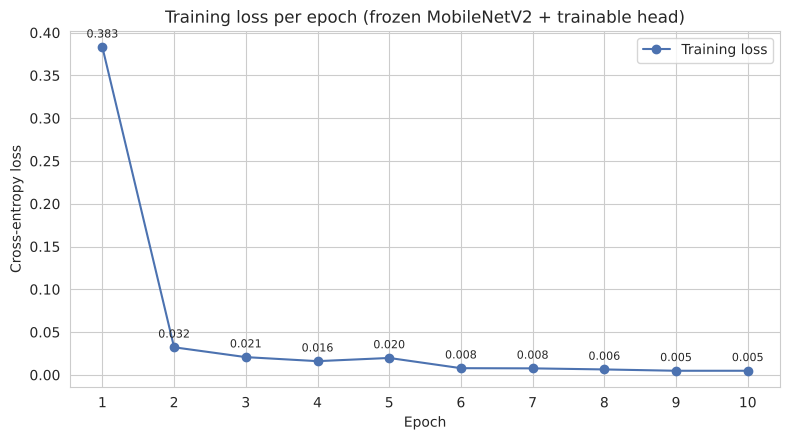

In [14]:
# Training Loss Visualisation
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(history_df["epoch"], history_df["train_loss"], marker="o", color="#4C72B0", label="Training loss")
for e, l in zip(history_df["epoch"], history_df["train_loss"]):
    ax.annotate(f"{l:.3f}", (e, l), textcoords="offset points", xytext=(0, 7), ha="center", fontsize=8)
ax.set_xlabel("Epoch"); ax.set_ylabel("Cross-entropy loss")
ax.set_title("Training loss per epoch (frozen MobileNetV2 + trainable head)")
ax.set_xticks(history_df["epoch"]); ax.legend()
plt.tight_layout(); plt.show()

## 3. Evaluation and Final Predictions

<font color=red>[10 marks]</font>

After training the model, it is essential to evaluate how well it performs on unseen data. Evaluation helps us understand whether the model has learned generalisable patterns or has simply memorised the training data.

In this section, we:
- Measure model performance using validation accuracy
- Analyse predictions at the individual data-point level
- Examine model behavior using diagnostic plots

### 3.1 Evaluation Metrics and Bias-Variance Tradeoff

<font color=red>[6 marks]</font>

#### **3.1.1** Calculate Appropriate Evaluation Metrics to Assess Model Performance <font color=red>[3 marks]</font>

For this multi-class classification problem, we use **accuracy** as the primary evaluation metric.

Accuracy measures the proportion of validation samples that are correctly classified by the model. Since the dataset is reasonably balanced across classes, accuracy provides a reliable indication of overall performance.

Validation accuracy      : 0.9972  (359/360 correct)
Validation loss          : 0.0087
Train accuracy (no aug.) : 1.0000
Macro precision / recall / F1 : 0.9973 / 0.9972 / 0.9972

Per-class classification report (validation):
                 precision    recall  f1-score   support

        crazing     1.0000    1.0000    1.0000        60
      inclusion     1.0000    0.9833    0.9916        60
        patches     1.0000    1.0000    1.0000        60
 pitted_surface     1.0000    1.0000    1.0000        60
rolled-in_scale     1.0000    1.0000    1.0000        60
      scratches     0.9836    1.0000    0.9917        60

       accuracy                         0.9972       360
      macro avg     0.9973    0.9972    0.9972       360
   weighted avg     0.9973    0.9972    0.9972       360



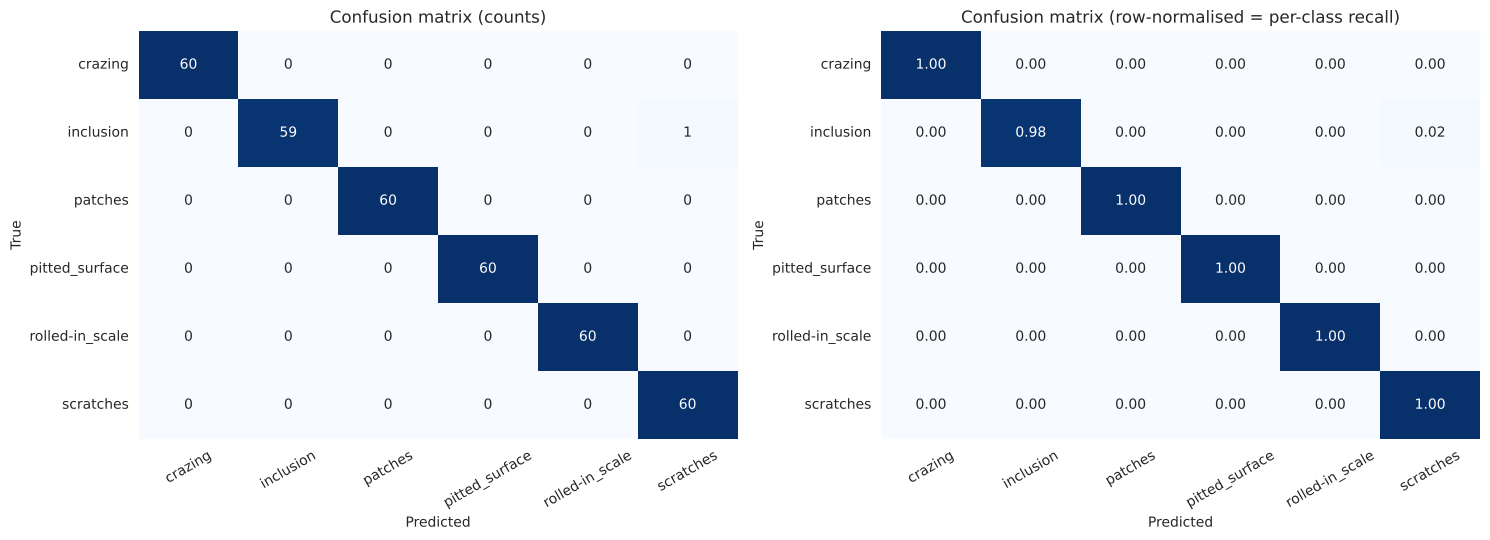

,per-class accuracy
crazing,100.00%
inclusion,98.33%
patches,100.00%
pitted_surface,100.00%
rolled-in_scale,100.00%
scratches,100.00%


In [15]:
# Model Evaluation
val_loss, val_acc, y_pred, y_true, y_prob = evaluate(model, val_loader, criterion, device)
_, train_acc_eval, *_ = evaluate(model, DataLoader(datasets.ImageFolder(TRAIN_DIR, transform=val_transforms),
                                                    batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS),
                                  criterion, device)

prec, rec, f1, _ = precision_recall_fscore_support(y_true, y_pred, average="macro")
print(f"Validation accuracy      : {accuracy_score(y_true, y_pred):.4f}  ({(y_pred == y_true).sum()}/{len(y_true)} correct)")
print(f"Validation loss          : {val_loss:.4f}")
print(f"Train accuracy (no aug.) : {train_acc_eval:.4f}")
print(f"Macro precision / recall / F1 : {prec:.4f} / {rec:.4f} / {f1:.4f}\n")
print("Per-class classification report (validation):")
print(classification_report(y_true, y_pred, target_names=class_names, digits=4))

# Confusion matrix
cm = confusion_matrix(y_true, y_pred)
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names, ax=axes[0], cbar=False)
axes[0].set_title("Confusion matrix (counts)"); axes[0].set_xlabel("Predicted"); axes[0].set_ylabel("True")
cm_norm = cm / cm.sum(axis=1, keepdims=True)
sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Blues", xticklabels=class_names, yticklabels=class_names, ax=axes[1], cbar=False)
axes[1].set_title("Confusion matrix (row-normalised = per-class recall)"); axes[1].set_xlabel("Predicted"); axes[1].set_ylabel("True")
for a in axes:
    a.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()

per_class_acc = pd.Series(cm.diagonal() / cm.sum(axis=1), index=class_names, name="per-class accuracy")
display(per_class_acc.to_frame().style.format("{:.2%}"))

**Interpretation of the metrics:**
- **Validation accuracy is 99.72%** (359 of 360 images correct), against a 16.7% random baseline. Macro precision, recall and F1 are all about 0.997. Because the classes are balanced, accuracy and macro-F1 agree, which confirms accuracy is a reliable headline metric here.
- Five of six classes (crazing, patches, pitted surface, rolled-in scale, scratches) reach **100% recall**. The only error is one *inclusion* image predicted as *scratches*. That gives inclusion a recall of 98.3% and scratches a precision of 98.4%.
- Inclusion vs scratches is a plausible confusion: both appear as thin, elongated dark or bright streaks along the rolling direction.
- Precision and recall are reported alongside accuracy because, in production, a missed defect (low recall) usually costs more than a false alarm.

#### **3.1.2** Dataset Diagnostics <font color=red>[3 marks]</font>

Beyond accuracy, diagnostic analysis helps assess whether the model is underfitting, overfitting, or generalising well

Analyse this using training and validation loss trends, along with dataset class distribution.

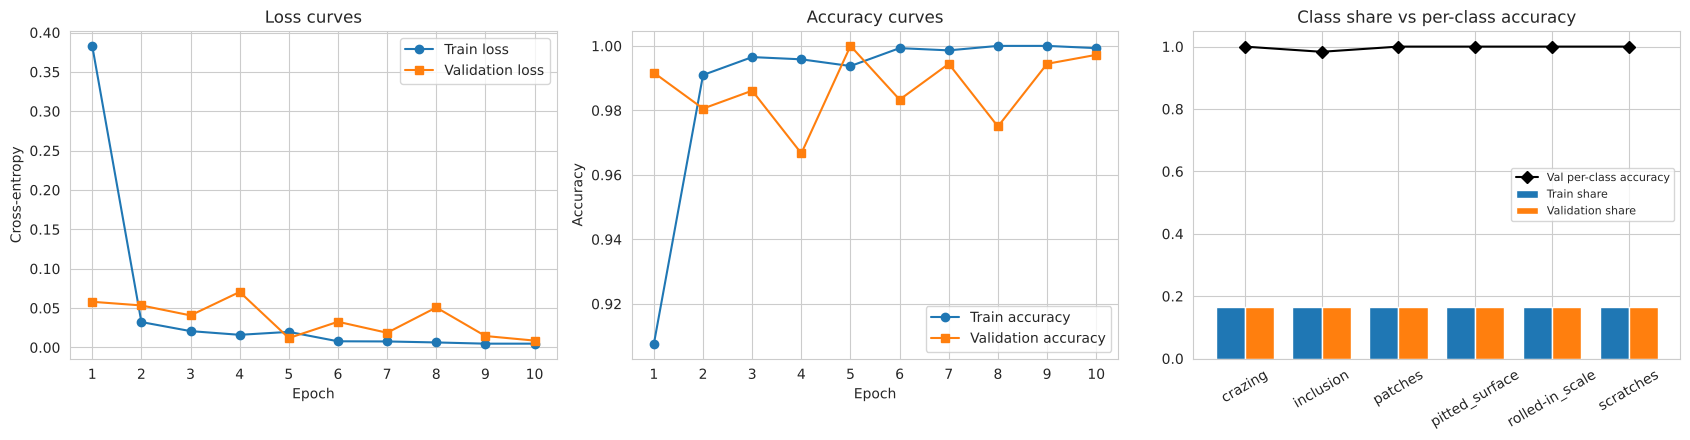

Final epoch -> train loss 0.0048, val loss 0.0087, gap (val - train) = +0.0039
Final epoch -> train acc  0.9993, val acc  0.9972, gap (train - val) = +0.0021
Best val acc 1.0000 at epoch 5


,epoch,train_loss,train_acc,val_loss,val_acc,time_s
0,1,0.3830,0.9076,0.0580,0.9917,56.0911
1,2,0.0322,0.9910,0.0533,0.9806,52.6877
2,3,0.0207,0.9965,0.0407,0.9861,55.0190
3,4,0.0160,0.9958,0.0705,0.9667,55.3039
4,5,0.0197,0.9938,0.0119,1.0000,53.9994
5,6,0.0078,0.9993,0.0326,0.9833,54.1201
6,7,0.0076,0.9986,0.0186,0.9944,53.6149
7,8,0.0063,1.0000,0.0507,0.9750,55.0386
8,9,0.0048,1.0000,0.0145,0.9944,54.0046
9,10,0.0048,0.9993,0.0087,0.9972,52.7428


In [16]:
# Training and Validation Loss Analysis
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

axes[0].plot(history_df["epoch"], history_df["train_loss"], "o-", label="Train loss")
axes[0].plot(history_df["epoch"], history_df["val_loss"], "s-", label="Validation loss")
axes[0].set_title("Loss curves"); axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Cross-entropy"); axes[0].legend()

axes[1].plot(history_df["epoch"], history_df["train_acc"], "o-", label="Train accuracy")
axes[1].plot(history_df["epoch"], history_df["val_acc"], "s-", label="Validation accuracy")
axes[1].set_title("Accuracy curves"); axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Accuracy"); axes[1].legend()

x = np.arange(num_classes); w = 0.38
axes[2].bar(x - w/2, dist_df["train"] / dist_df["train"].sum(), w, label="Train share")
axes[2].bar(x + w/2, dist_df["validation"] / dist_df["validation"].sum(), w, label="Validation share")
axes[2].plot(x, per_class_acc.values, "kD-", label="Val per-class accuracy")
axes[2].set_xticks(x); axes[2].set_xticklabels(class_names, rotation=30); axes[2].set_ylim(0, 1.05)
axes[2].set_title("Class share vs per-class accuracy"); axes[2].legend(fontsize=8)
for a in axes[:2]:
    a.set_xticks(history_df["epoch"])
plt.tight_layout(); plt.show()

last = history_df.iloc[-1]
print(f"Final epoch -> train loss {last.train_loss:.4f}, val loss {last.val_loss:.4f}, "
      f"gap (val - train) = {last.val_loss - last.train_loss:+.4f}")
print(f"Final epoch -> train acc  {last.train_acc:.4f}, val acc  {last.val_acc:.4f}, "
      f"gap (train - val) = {last.train_acc - last.val_acc:+.4f}")
print(f"Best val acc {history_df.val_acc.max():.4f} at epoch {int(history_df.loc[history_df.val_acc.idxmax(), 'epoch'])}")
display(history_df.round(4))

**Bias–variance diagnosis:**
- **No underfitting (low bias):** training loss falls from 0.38 to about 0.005 and training accuracy reaches about 100%. The frozen ImageNet features plus a small head are expressive enough for this task.
- **No meaningful overfitting (low variance):** validation loss also trends down, from 0.058 to 0.009, and ends close to training loss (gap about +0.004). Final validation accuracy (99.7%) is within 0.2 percentage points of training accuracy. A model that memorised the training data would show validation loss rising while training loss keeps falling, which does not happen here.
- **Epoch-to-epoch fluctuation:** validation accuracy moves between 96.7% and 100%, with dips at epochs 4 and 8. With only 360 validation images, one image is 0.28 percentage points, so these dips are 9–12 borderline images changing sides. A constant Adam learning rate of 1e-3 makes the head's decision boundary jitter slightly. A learning-rate decay schedule would smooth this.
- **Validation loss below training loss at epoch 1:** training loss is averaged *during* the epoch while the head is still learning, with dropout and flip augmentation active. Validation loss is measured *after* the epoch with dropout off. This is expected, not a sign of leakage.
- **Class distribution:** every class is exactly 1/6 of both splits, and per-class accuracy is flat at 98–100%. Performance is not driven by class frequency, so there is no hidden bias toward a majority class.

**Conclusion:** The model is in the "good fit" region: low bias and low variance. The frozen backbone acts as a strong regulariser, and dropout plus augmentation in the head keeps the train–validation gap small.

### 3.2 Prediction Analysis

<font color=red>[4 marks]</font>

Overall accuracy provides a summary metric, but it does not reveal how individual predictions contribute to that score.

To better understand model behavior, we examine predictions at the individual image level, highlighting both correct and incorrect classifications.

#### **3.2.1** Visualise the prediction on a few sample images from validation set <font color=red>[4 marks]</font>

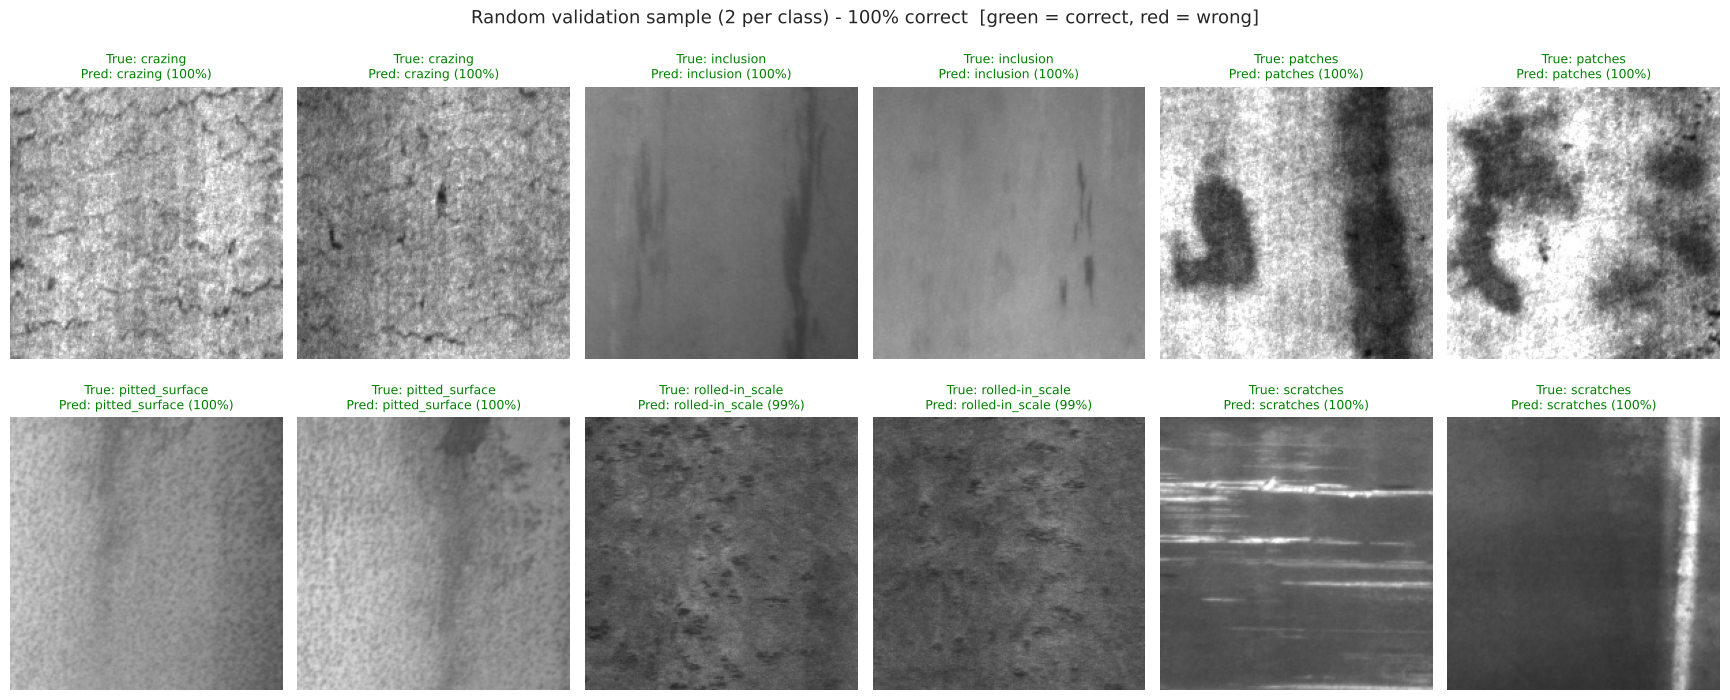

Misclassified validation images: 1 / 360


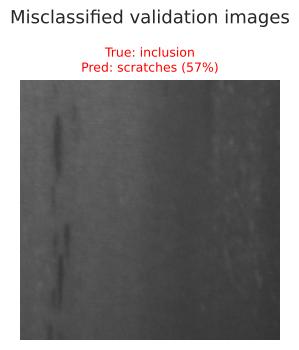

,file,true,predicted,confidence
0,inclusion_294.jpg,inclusion,scratches,56.6%


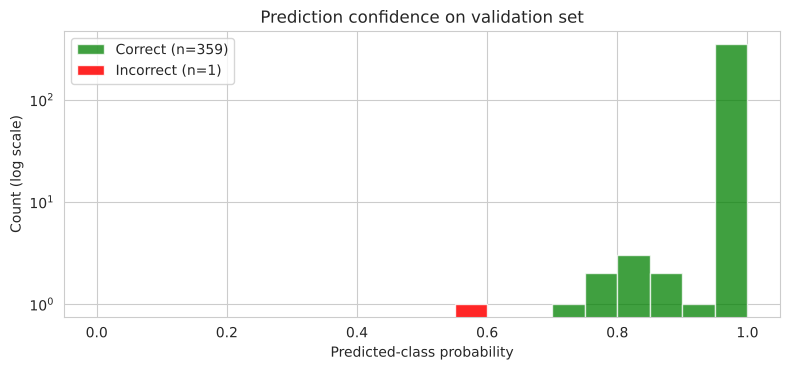

In [17]:
# Visualisation of Validation Predictions
rng = np.random.default_rng(SEED)
correct_idx = np.where(y_pred == y_true)[0]
wrong_idx   = np.where(y_pred != y_true)[0]

def show_predictions(indices, title, ncols=6):
    ncols = min(ncols, len(indices))
    nrows = int(np.ceil(len(indices) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(2.9 * ncols, 3.6 * nrows))
    axes = np.atleast_1d(axes).ravel()
    for ax in axes: ax.axis("off")
    for ax, i in zip(axes, indices):
        path, _ = val_dataset.samples[i]
        ok = y_pred[i] == y_true[i]
        ax.imshow(Image.open(path), cmap="gray")
        ax.set_title(f"True: {class_names[y_true[i]]}\nPred: {class_names[y_pred[i]]} ({y_prob[i, y_pred[i]]:.0%})",
                     fontsize=9, color="green" if ok else "red")
        for s in ax.spines.values():
            s.set_visible(True); s.set_color("green" if ok else "red"); s.set_linewidth(3)
    fig.suptitle(title, fontsize=13, y=1.0)
    plt.tight_layout(h_pad=2.5); plt.show()

# (a) Random sample: two images per class, so every class is represented
sample_idx = np.concatenate([rng.choice(np.where(y_true == c)[0], 2, replace=False) for c in range(num_classes)])
show_predictions(sample_idx, f"Random validation sample (2 per class) - {np.mean(y_pred[sample_idx] == y_true[sample_idx]):.0%} correct  "
                             "[green = correct, red = wrong]")

# (b) All misclassified validation images (up to 12)
print(f"Misclassified validation images: {len(wrong_idx)} / {len(y_true)}")
if len(wrong_idx):
    show_predictions(wrong_idx[:12], "Misclassified validation images", ncols=4)
    err_df = pd.DataFrame({"file": [Path(val_dataset.samples[i][0]).name for i in wrong_idx],
                           "true": [class_names[y_true[i]] for i in wrong_idx],
                           "predicted": [class_names[y_pred[i]] for i in wrong_idx],
                           "confidence": [y_prob[i, y_pred[i]] for i in wrong_idx]})
    display(err_df.style.format({"confidence": "{:.1%}"}))

# (c) Confidence distribution: correct vs incorrect predictions
conf = y_prob.max(1)
plt.figure(figsize=(8, 3.8))
plt.hist(conf[correct_idx], bins=20, range=(0, 1), alpha=0.75, label=f"Correct (n={len(correct_idx)})", color="green")
if len(wrong_idx):
    plt.hist(conf[wrong_idx], bins=20, range=(0, 1), alpha=0.85, label=f"Incorrect (n={len(wrong_idx)})", color="red")
plt.yscale("log"); plt.xlabel("Predicted-class probability"); plt.ylabel("Count (log scale)")
plt.title("Prediction confidence on validation set"); plt.legend(); plt.tight_layout(); plt.show()

**Observations from the prediction analysis:**
- In the random sample (2 images per class), every prediction is correct with 99–100% confidence. The model has learned clearly separable signatures for each defect, for example:
  - **crazing:** network-like fine cracks
  - **patches:** large dark blotches
  - **rolled-in scale:** scattered small dark flakes
  - **scratches:** long bright or dark lines
- The single error (`inclusion_294.jpg`, inclusion → scratches) has only **about 57% confidence**, unlike the near-certain correct predictions. The image shows a long vertical chain of dark inclusions, which looks like a linear scratch.
- The confidence histogram shows correct predictions clustered near 100% and the one mistake in the low-confidence region. A confidence threshold (for example, sending predictions below 80% to a human inspector) would catch such borderline cases with very little extra manual workload.

## 4 Conclusion 

<font color =red> [5 marks] </font>

### 4.1 Conclusion and insights

<font color =red> [5 marks] </font>

#### **4.1.1** Conclude with the insights drawn and final outcomes and results. Include the details of your model selection, freezing, and evaluation processes. <font color =red> [5 marks] </font>


*Answer below:*

**Final outcome:** A MobileNetV2 transfer-learning model, with a frozen ImageNet backbone and only a small classification head trained, classifies the six NEU steel-surface defect types with **99.72% validation accuracy** (359/360). Macro precision, recall and F1 are about 0.997. This was achieved with 1,440 training images, 10 epochs and about 9 minutes of CPU-only training.

**1. Data understanding and preparation**
- There are 1,800 images (1,440 train, 360 validation) across 6 classes. The data is perfectly balanced (240/60 per class), so accuracy is a fair metric and no class weighting was needed.
- `ImageFolder` derived the labels from folder names (crazing = 0 … scratches = 5). The XML bounding-box annotations were not needed for image-level classification.
- Preprocessing matched ImageNet expectations: grayscale → 3 channels, resize 200 → 224, ImageNet mean/std normalisation. Random horizontal and vertical flips were applied to training images only. The training loader is shuffled; the validation loader is not.

**2. Model selection**
- MobileNetV2 (ImageNet `IMAGENET1K_V1`) was chosen for its efficiency: about 3.5M parameters, built from depthwise-separable inverted-residual blocks.
- Its early and mid-level filters capture edges, blobs and textures. These are exactly the cues that separate surface defects, even though the source domain is natural photos.
- Its small footprint also makes it realistic to deploy on edge or line-side inspection hardware.

**3. Freezing strategy**
- The full feature extractor (19 blocks, **2,223,872 parameters**) was frozen, and its BatchNorm layers were kept in `eval()` mode.
- Only a new head was trained: Dropout → Linear 1280→256 → ReLU → Dropout → Linear 256→6, with **329,478 parameters (12.9% of the model)**.
- A check after training confirmed the backbone weights and BN statistics were unchanged.
- Training was done with Adam (lr 1e-3, weight decay 1e-4) and cross-entropy loss for 10 epochs at batch size 32.

**4. Evaluation and diagnostics**
- Training loss fell from 0.38 to 0.005. Validation loss tracked it down to 0.009, with a final train–validation accuracy gap of only 0.2 percentage points. This indicates **low bias and low variance**, with no overfitting despite the small dataset.
- Five classes reached 100% recall. The only error was one *inclusion* image predicted as *scratches* with low (57%) confidence. Both classes show elongated streaks along the rolling direction.
- Validation accuracy fluctuated between 96.7% and 100% across epochs. This is about ±10 images out of 360 and reflects the small validation set and a constant learning rate.

**Key insights**
- Pretrained ImageNet features transfer very well to industrial texture classification. A frozen backbone alone almost solves NEU-DET, so full fine-tuning is unnecessary for this dataset.
- Partial transfer learning gives an excellent accuracy-to-cost ratio. Only about 13% of the parameters are trained, training is fast on CPU, and the risk of overfitting is low. This supports the business case of reusing pretrained models instead of training from scratch.
- Prediction confidence is informative: errors are low-confidence. A human-in-the-loop threshold would make the system safer in production.

**Limitations and next steps**
- 360 validation images is a small sample, so each image is 0.28 percentage points. The validation set also served as the test set. A held-out test set or k-fold cross-validation would give a tighter estimate.
- Possible improvements:
  - Add a learning-rate scheduler to smooth the validation curve.
  - Unfreeze the last few backbone blocks at a low learning rate for harder datasets.
  - Use stronger augmentation (brightness/contrast, small rotations) for robustness to lighting changes on a real line.
  - Use the provided bounding-box annotations to extend the work to defect *localisation* (object detection).